In [1]:
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

# Dataset paths
DATA_DIR = Path("../data")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Image configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Train directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.21.0
Train directory: ..\data\train
Validation directory: ..\data\val
Test directory: ..\data\test
Image size: (224, 224)
Batch size: 32


In [2]:
# Load training dataset

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

# Load validation dataset

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Get class names
class_names = train_ds.class_names

print("\nNumber of classes:", len(class_names))
print("\nClasses:")
for i, name in enumerate(class_names):
    print(i, "->", name)

Found 15474 files belonging to 15 classes.
Found 3310 files belonging to 15 classes.

Number of classes: 15

Classes:
0 -> Corn___Cercospora_leaf_spot Gray_leaf_spot
1 -> Corn___Common_rust
2 -> Corn___Northern_Leaf_Blight
3 -> Corn___healthy
4 -> Potato___Early_blight
5 -> Potato___Late_blight
6 -> Potato___healthy
7 -> Tomato___Bacterial_spot
8 -> Tomato___Early_blight
9 -> Tomato___Late_blight
10 -> Tomato___Leaf_Mold
11 -> Tomato___Septoria_leaf_spot
12 -> Tomato___Target_Spot
13 -> Tomato___Tomato_Yellow_Leaf_Curl_Virus
14 -> Tomato___healthy


In [3]:
# Data augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


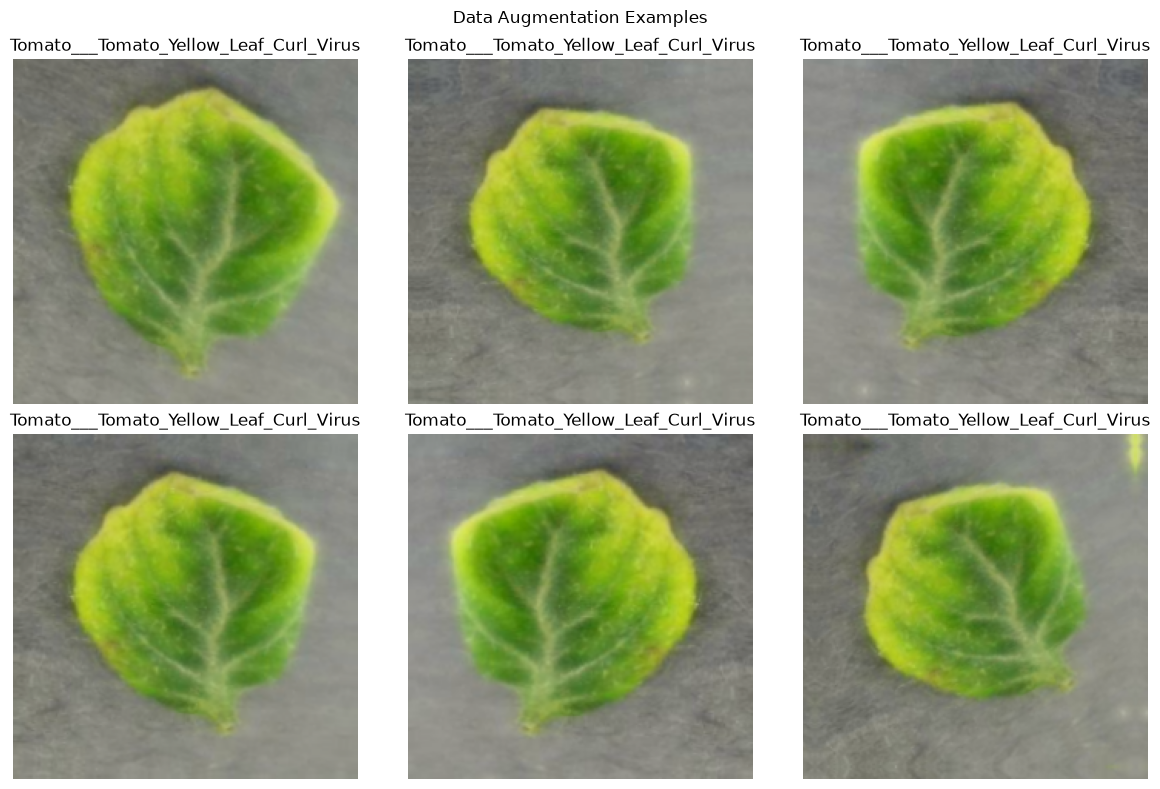

In [4]:
# Display augmented versions of one training image

for images, labels in train_ds.take(1):
    sample_image = images[0]
    sample_label = labels[0]

plt.figure(figsize=(12, 8))

for i in range(6):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, 0),
        training=True
    )[0]

    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.cast(augmented_image, tf.uint8))
    plt.title(class_names[sample_label])
    plt.axis("off")

plt.suptitle("Data Augmentation Examples")
plt.tight_layout()
plt.show()

In [5]:
# Apply augmentation only to the training dataset

AUTOTUNE = tf.data.AUTOTUNE

train_ds_augmented = train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    ),
    num_parallel_calls=AUTOTUNE
)

# Optimize dataset loading
train_ds_augmented = train_ds_augmented.prefetch(AUTOTUNE)

# Validation dataset: no augmentation
val_ds = val_ds.prefetch(AUTOTUNE)

print("Training augmentation connected.")
print("Validation data kept without augmentation.")

Training augmentation connected.
Validation data kept without augmentation.


In [6]:
# Verify the training batch

for images, labels in train_ds_augmented.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [7]:
# Build a simple CNN baseline model

baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values from 0-255 to 0-1
    tf.keras.layers.Rescaling(1.0 / 255),

    # Convolution block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # Convolution block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # Convolution block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # Classifier
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,183 (371.81 KB)

 Trainable params: 95,183 (371.81 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compile the baseline CNN

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline model compiled successfully.")

Baseline model compiled successfully.


In [9]:
# Training callbacks

from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "baseline_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Training callbacks created.")
print("Best model will be saved to:", MODEL_DIR / "baseline_best.keras")

Training callbacks created.
Best model will be saved to: ..\models\baseline_best.keras


In [10]:
# Train the baseline CNN

EPOCHS = 10

history = baseline_model.fit(
    train_ds_augmented,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Baseline training completed.")

Epoch 1/10


c:\Agro Care Ai\Agro Care AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4015 - loss: 1.9086
Epoch 1: val_loss improved from None to 1.47817, saving model to ..\models\baseline_best.keras

Epoch 1: finished saving model to ..\models\baseline_best.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 600s 1s/step - accuracy: 0.4015 - loss: 1.9086 - val_accuracy: 0.5148 - val_loss: 1.4782
Epoch 2/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.5799 - loss: 1.2895
Epoch 2: val_loss improved from 1.47817 to 1.13832, saving model to ..\models\baseline_best.keras

Epoch 2: finished saving model to ..\models\baseline_best.keras
484/484 ━━━━━━━━━━━━━━━━━━━━ 357s 736ms/step - accuracy: 0.5799 - loss: 1.2895 - val_accuracy: 0.5903 - val_loss: 1.1383
Epoch 3/10
484/484 ━━━━━━━━━━━━━━━━━━━━ 0s 936ms/step - accuracy: 0.6632 - loss: 1.0142
Epoch 3: val_loss improved from 1.13832 to 0.93088, saving model to ..\models\baseline_best.keras

Epoch 3: finished saving model to ..\models\baseline_best.keras
484/484 ━━━━━━━━━━━━━━━━━

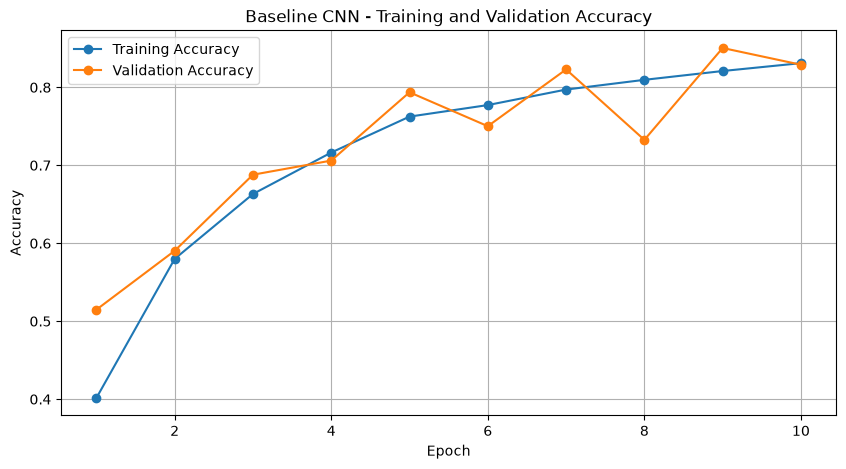

In [11]:
# Plot training and validation performance

train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_acc) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_acc, marker="o", label="Validation Accuracy")

plt.title("Baseline CNN - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

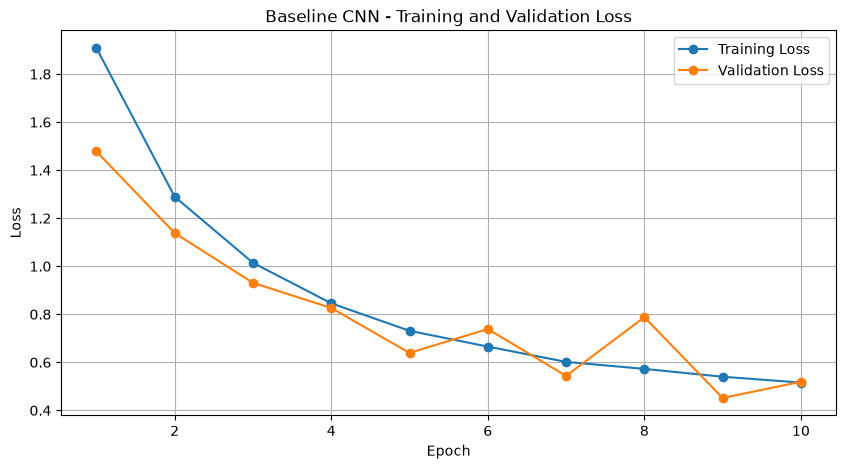

In [12]:
# Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")

plt.title("Baseline CNN - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
# Load the best baseline model

best_baseline_model = tf.keras.models.load_model(
    "../models/baseline_best.keras"
)

print("Best baseline model loaded successfully.")

Best baseline model loaded successfully.


In [15]:
# Load the test dataset

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Save class names before prefetching
test_class_names = test_ds.class_names

# Optimize test dataset loading
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test dataset loaded successfully.")
print("Test images: 3331")
print("Test classes:", len(test_class_names))
print("Classes match:", test_class_names == class_names)

Found 3331 files belonging to 15 classes.
Test dataset loaded successfully.
Test images: 3331
Test classes: 15
Classes match: True


In [16]:
# Generate predictions on the test set

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_baseline_model.predict(images, verbose=0)

    predicted_classes = tf.argmax(predictions, axis=1).numpy()

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

print("Predictions generated successfully.")
print("True labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Predictions generated successfully.
True labels: 3331
Predicted labels: 3331


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate overall metrics
test_accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Baseline CNN Test Results")
print("=" * 40)
print(f"Test Accuracy   : {test_accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1 Score  : {macro_f1:.4f}")

Baseline CNN Test Results
Test Accuracy   : 0.8727
Macro Precision : 0.8410
Macro Recall    : 0.8297
Macro F1 Score  : 0.8303


In [18]:
# Detailed classification report

report = classification_report(
    y_true,
    y_pred,
    target_names=test_class_names,
    digits=4,
    zero_division=0
)

print(report)

                                            precision    recall  f1-score   support

Corn___Cercospora_leaf_spot Gray_leaf_spot     0.6162    0.7821    0.6893        78
                        Corn___Common_rust     0.9890    0.9944    0.9917       180
               Corn___Northern_Leaf_Blight     0.8478    0.7852    0.8153       149
                            Corn___healthy     0.9943    1.0000    0.9972       175
                     Potato___Early_blight     0.8133    0.9000    0.8544       150
                      Potato___Late_blight     0.8029    0.7333    0.7666       150
                          Potato___healthy     0.8235    0.5833    0.6829        24
                   Tomato___Bacterial_spot     0.9085    0.9313    0.9198       320
                     Tomato___Early_blight     0.6643    0.6333    0.6485       150
                      Tomato___Late_blight     0.8692    0.6481    0.7425       287
                        Tomato___Leaf_Mold     0.8582    0.7986    0.8273  

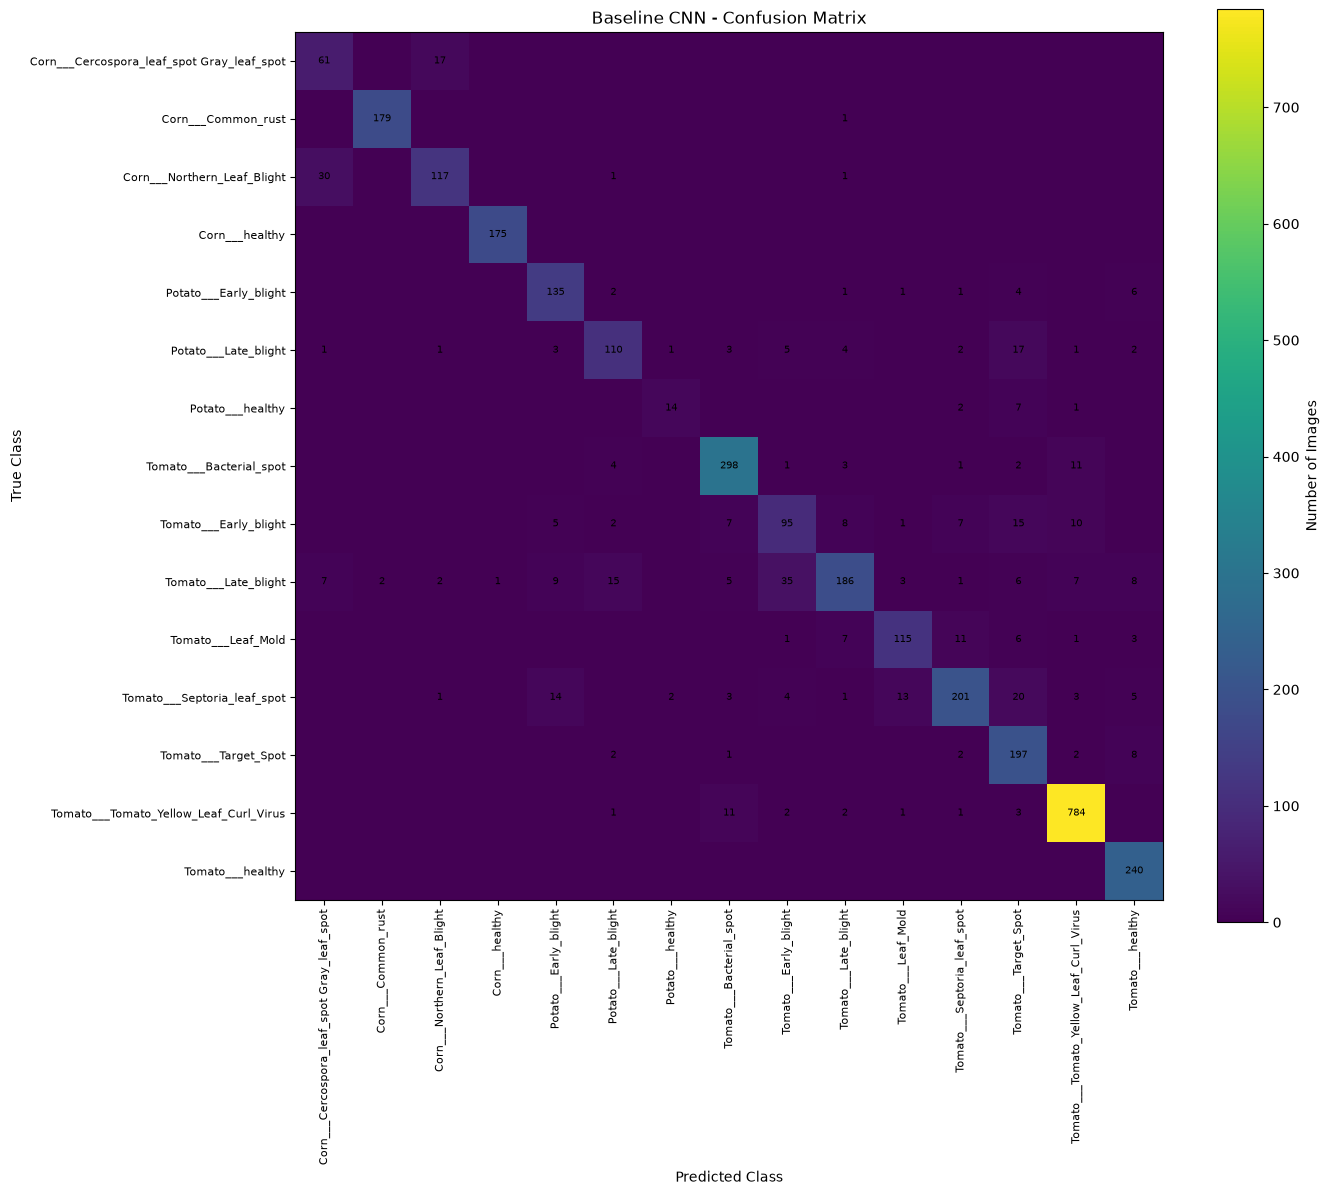

In [19]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

plt.imshow(cm, interpolation="nearest")

plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(len(test_class_names)),
    test_class_names,
    rotation=90,
    fontsize=8
)

plt.yticks(
    range(len(test_class_names)),
    test_class_names,
    fontsize=8
)

# Add numbers inside cells
for i in range(len(test_class_names)):
    for j in range(len(test_class_names)):
        if cm[i, j] > 0:
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center",
                fontsize=7
            )

plt.colorbar(label="Number of Images")
plt.tight_layout()
plt.show()

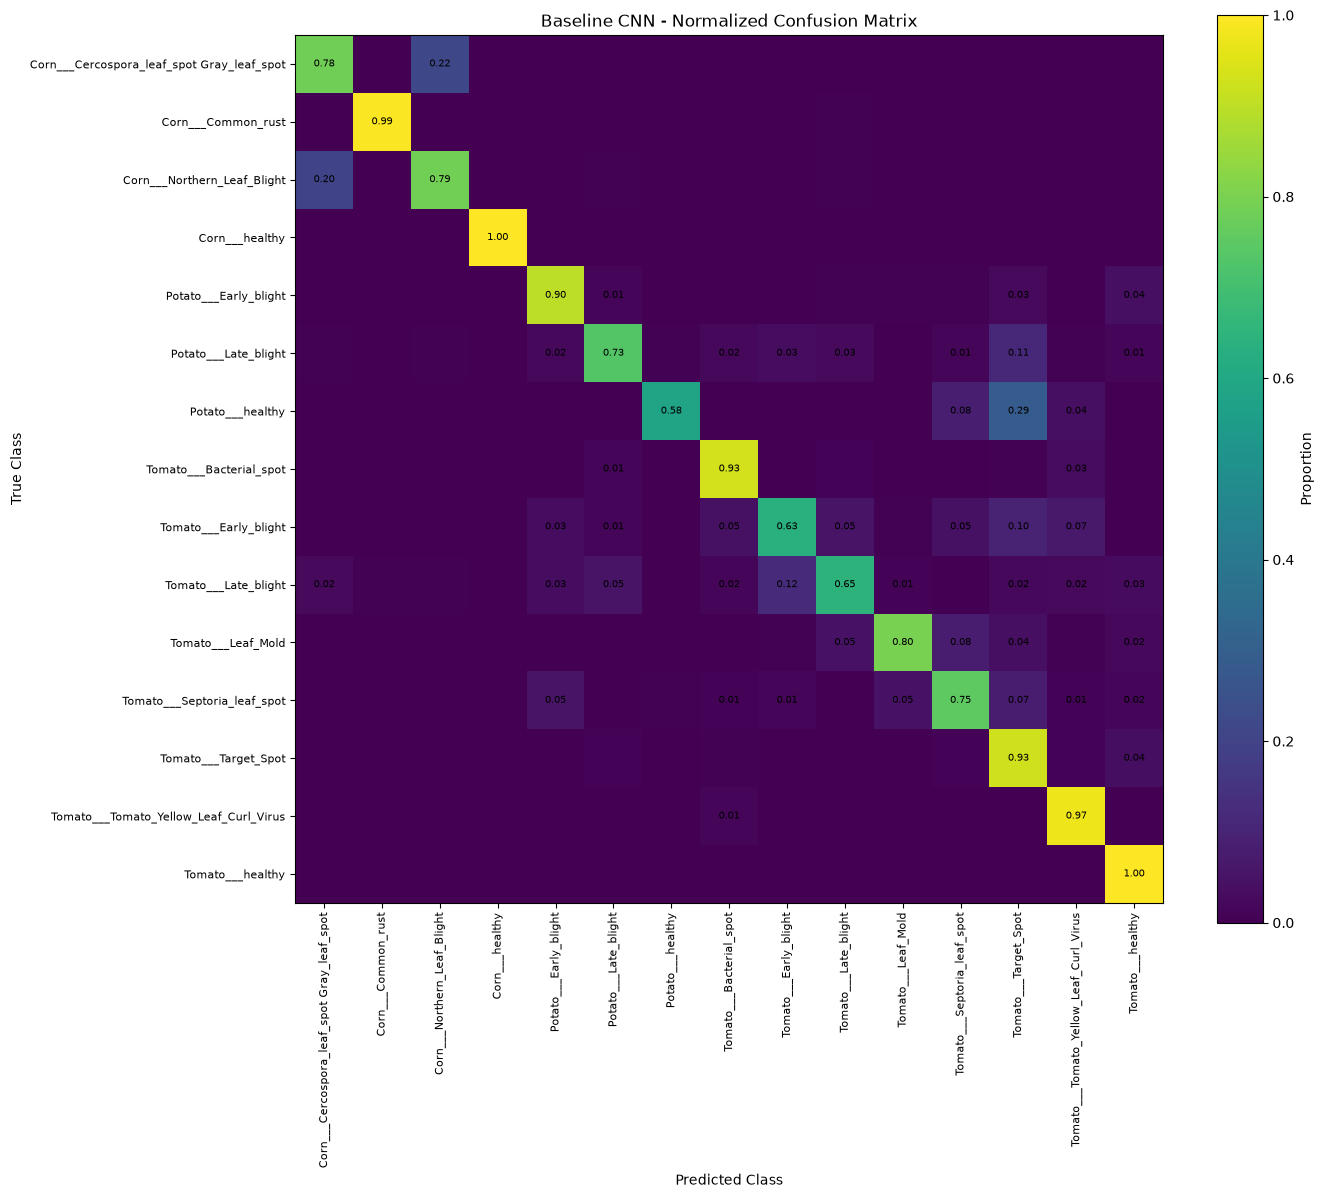

In [20]:
# Normalized confusion matrix

import numpy as np

cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(14, 12))

plt.imshow(cm_normalized, interpolation="nearest")

plt.title("Baseline CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(len(test_class_names)),
    test_class_names,
    rotation=90,
    fontsize=8
)

plt.yticks(
    range(len(test_class_names)),
    test_class_names,
    fontsize=8
)

for i in range(len(test_class_names)):
    for j in range(len(test_class_names)):
        if cm_normalized[i, j] > 0.01:
            plt.text(
                j,
                i,
                f"{cm_normalized[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=7
            )

plt.colorbar(label="Proportion")
plt.tight_layout()
plt.show()

In [21]:
# Save baseline evaluation results

import json

results = {
    "model": "Baseline CNN",
    "test_images": len(y_true),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "best_validation_loss": float(min(history.history["val_loss"])),
    "final_training_accuracy": float(history.history["accuracy"][-1]),
    "final_validation_accuracy": float(history.history["val_accuracy"][-1])
}

REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(REPORTS_DIR / "baseline_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Baseline results saved to:")
print(REPORTS_DIR / "baseline_results.json")

Baseline results saved to:
..\reports\baseline_results.json
